# Exploratory Data Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

In [2]:
df = pd.read_csv("../data/processed/cleaned_data.csv")

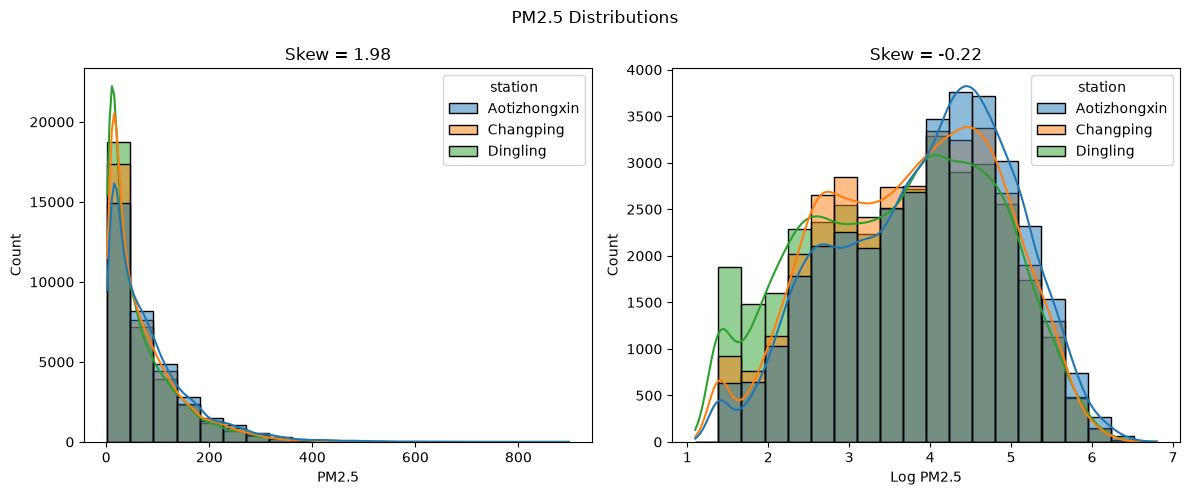

In [3]:
# PM2.5 distribution (histogram)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(
    df,
    x="PM2.5",
    hue="station",
    kde=True,
    bins=20,
    ax=ax[0]
)
ax[0].set_title(f"Skew = {df["PM2.5"].skew():.2f}")

sns.histplot(
    x=np.log1p(df["PM2.5"]),
    hue=df["station"],
    kde=True,
    bins=20,
    ax=ax[1]
)
ax[1].set_xlabel("Log PM2.5")
ax[1].set_title(f"Skew = {np.log1p(df["PM2.5"]).skew():.2f}")

plt.suptitle("PM2.5 Distributions")

plt.tight_layout()
#plt.savefig("../reports/figures/pm25_distributions.png", dpi=300)
plt.show()

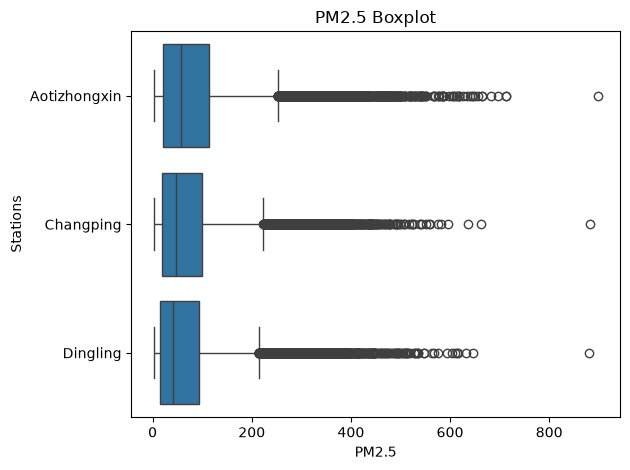

In [4]:
# PM2.5 distribution (boxplot)
ax = sns.boxplot(
    df,
    x="PM2.5",
    y="station"
)
ax.set_ylabel("Stations")
ax.set_title("PM2.5 Boxplot")

plt.tight_layout()
#plt.savefig("../reports/figures/pm25_boxplot.png", dpi=300)
plt.show()

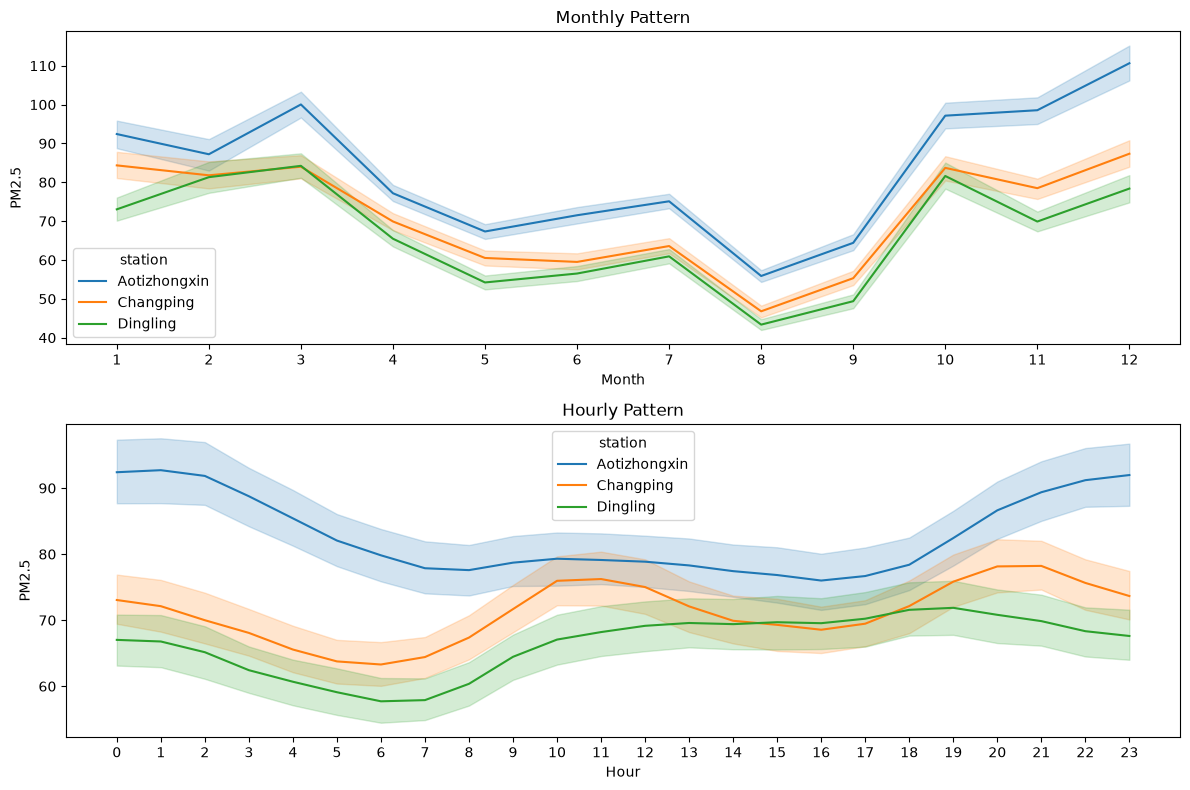

In [5]:
# Diurnal and seasonal PM2.5 cycles
fig, ax = plt.subplots(2, 1, figsize=(12, 8))

sns.lineplot(
    df,
    x="month",
    y="PM2.5",
    hue="station",
    ax=ax[0]
)
ax[0].set_xlabel("Month")
ax[0].set_xticks(range(1, 13))
ax[0].set_title("Monthly Pattern")

sns.lineplot(
    df,
    x="hour",
    y="PM2.5",
    hue="station",
    ax=ax[1]
)
ax[1].set_xlabel("Hour")
ax[1].set_xticks(range(0, 24))
ax[1].set_title("Hourly Pattern")

plt.tight_layout()
#plt.savefig("../reports/figures/pm25_cycles.png", dpi=300)
plt.show()

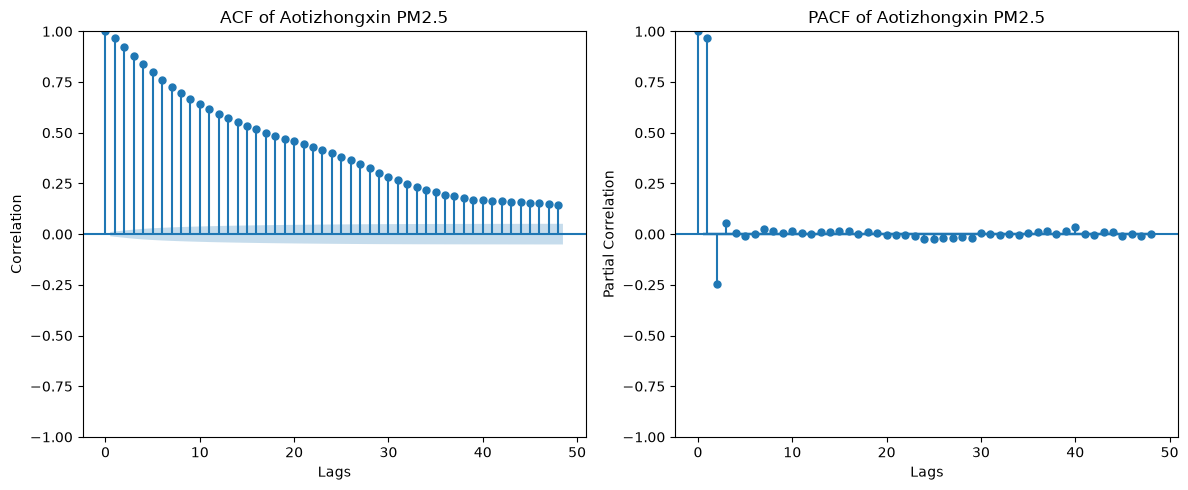

In [6]:
# ACF and PACF for lags
aot_pm25 = df[df["station"] == "Aotizhongxin"]["PM2.5"].dropna()

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

plot_acf(
    aot_pm25,
    lags=48,
    ax=ax[0],
    title="ACF of Aotizhongxin PM2.5"
)
ax[0].set_xlabel("Lags")
ax[0].set_ylabel("Correlation")

plot_pacf(
    aot_pm25,
    lags=48,
    ax=ax[1],
    title="PACF of Aotizhongxin PM2.5"
)
ax[1].set_xlabel("Lags")
ax[1].set_ylabel("Partial Correlation")

plt.tight_layout()
#plt.savefig("../reports/figures/acf_pacf_pm25.png", dpi=300)
plt.show()

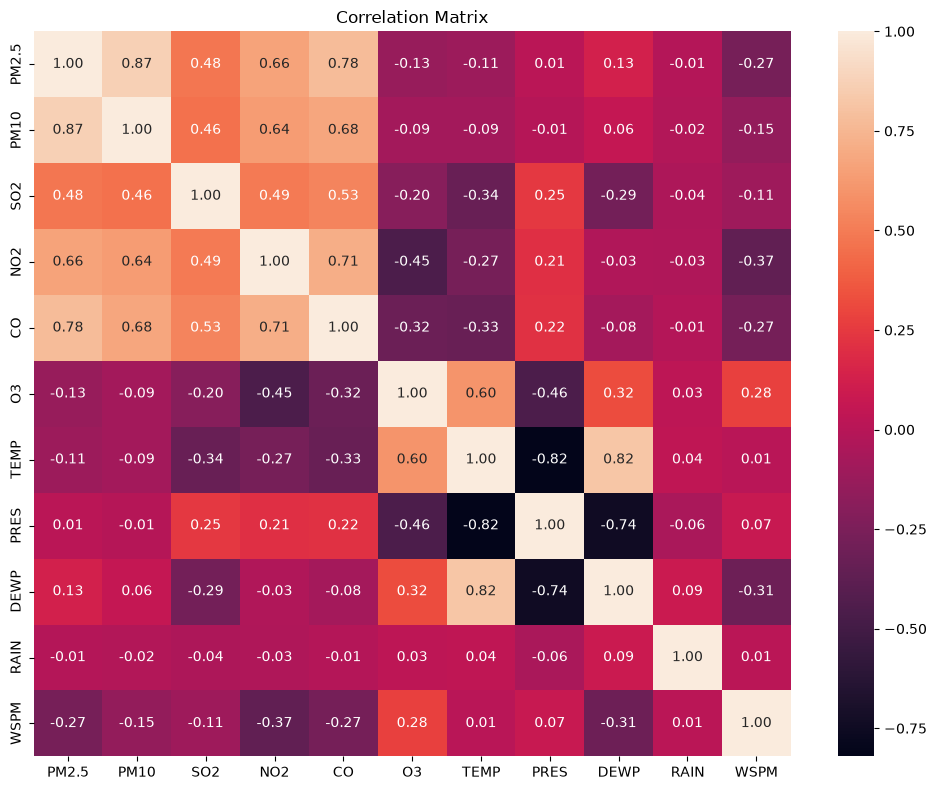

In [7]:
# Correlation heatmap
numerical_columns = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
corr_matrix = df[numerical_columns].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f"
)
plt.title("Correlation Matrix")

plt.tight_layout()
#plt.savefig("../reports/figures/corr_heatmap.png", dpi=300)
plt.show()

In [8]:
# Features with the highest correlation with target
abs(df[numerical_columns].corrwith(df["PM2.5"])).sort_values(ascending=False)

PM2.5    1.000000
PM10     0.867602
CO       0.776663
NO2      0.664282
SO2      0.475751
WSPM     0.269872
O3       0.131406
DEWP     0.127235
TEMP     0.109801
PRES     0.014332
RAIN     0.010219
dtype: float64

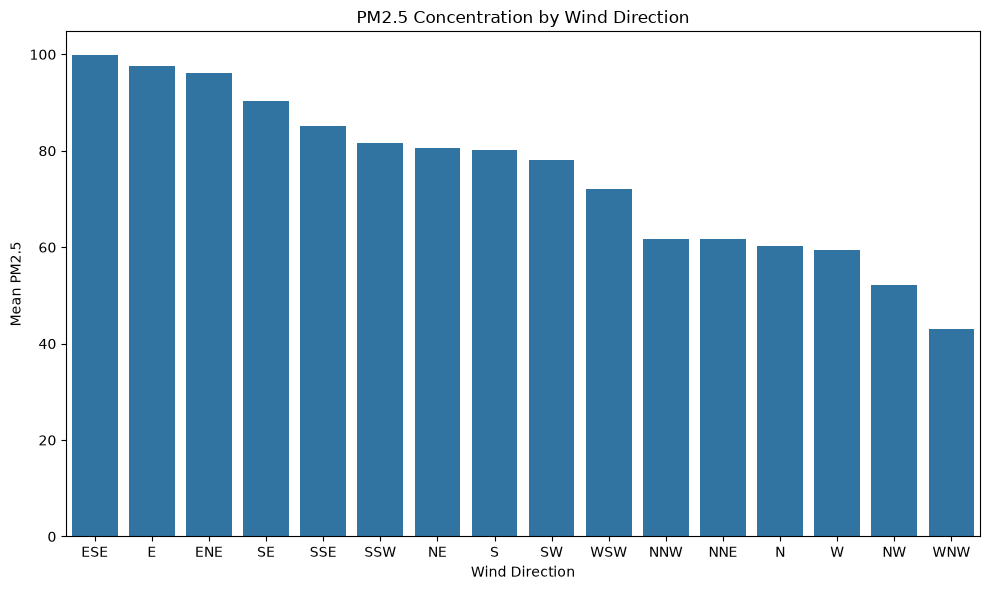

In [9]:
# Highest PM2.5 by wind direction
plt.figure(figsize=(10, 6))
sns.barplot(
    df,
    x="wd",
    y="PM2.5",
    errorbar=None,
    order=df.groupby("wd")["PM2.5"].mean().sort_values(ascending=False).index
)
plt.xlabel("Wind Direction")
plt.ylabel("Mean PM2.5")
plt.title("PM2.5 Concentration by Wind Direction")

plt.tight_layout()
#plt.savefig("../reports/figures/wind_direction_effect.png", dpi=300)
plt.show()